<a href="https://colab.research.google.com/github/harpreetsingh171190-cmyk/professional-portfolio-colab/blob/main/professional_portfolio_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from pathlib import Path
import json, textwrap, os, shutil, zipfile

PROJECT = Path('/content/COMP4651-professional-portfolio')
PROJECT.mkdir(parents=True, exist_ok=True)
PROJECT_FILES = {'README.md': '# COMP4651 Big Data & Machine Learning Portfolio\n\nA reproducible, cross-platform portfolio project demonstrating data generation, distributed processing, server-log analytics, model evaluation, and data visualization.\n\n> The included sample data is synthetic and intended for learning. Do not describe it as real operational data.\n\n## Portfolio highlights\n- **Data engineering:** deterministic dataset generation and validation-friendly CSV inputs\n- **Distributed computing:** PySpark word count\n- **Observability:** server access-log summary by path and HTTP status\n- **Machine learning:** reproducible regression pipeline with MAE, RMSE, and R²\n- **Visualization:** correlation heatmap, target distribution, and actual-vs-predicted chart\n- **Quality:** unit tests, reproducible random seeds, documented setup\n\n## Architecture\n```mermaid\nflowchart LR\n    A[Text and CSV inputs] --> B[Validation and preparation]\n    B --> C[PySpark word count]\n    B --> D[Log analytics]\n    B --> E[Regression pipeline]\n    E --> F[Metrics JSON]\n    B --> G[EDA charts]\n    E --> H[Actual vs predicted PNG]\n```\n\n## Run locally\nPython 3.10–3.12 recommended. Java 11/17 is recommended for local Spark.\n\n```bash\npython -m venv .venv\n# Windows PowerShell: .venv\\\\Scripts\\\\Activate.ps1\n# Kali/Linux: source .venv/bin/activate\npython -m pip install --upgrade pip\npip install -r requirements.txt\n\npython -m src.generate_data\npython -m src.word_count --input data/sample_text.txt --output outputs/word_count\npython -m src.log_analysis --input data/access.log --output outputs/log_summary.csv\npython -m src.ml_pipeline --input data/power_plant.csv --output-dir outputs/ml\npython -m src.visualize --input data/power_plant.csv --output-dir outputs/charts\npytest -q\n```\n\n## Outputs\nAfter running the commands:\n- `outputs/charts/correlation_heatmap.png`\n- `outputs/charts/energy_output_distribution.png`\n- `outputs/ml/actual_vs_predicted.png`\n- `outputs/ml/metrics.json`\n- `outputs/log_summary.csv`\n- `outputs/word_count/` (Spark output directory)\n\n## Run in cloud\nUpload the ZIP to a notebook environment or clone the repository. Install `requirements.txt`, run the data generator, then run visualization and ML scripts. Spark may require Java and provider-specific configuration. See `docs/PLATFORM_SETUP.md`.\n\n## Images\n- **Charts:** generated from data by `src/visualize.py` and `src/ml_pipeline.py`.\n- **AI illustrations:** use the ready-made prompts in `prompts/AI_IMAGE_PROMPTS.md` for a repository banner, architecture art, or vertical promo. Add text labels in an editor for accuracy.\n\n## Responsible presentation\nInclude the synthetic-data disclaimer in any public demo. Avoid uploading private logs, credentials, or licensed data without permission. The project is a learning portfolio and not a validated production forecasting system.\n', '.gitignore': '.venv/\nvenv/\n__pycache__/\n*.py[cod]\n.pytest_cache/\noutputs/*\n!outputs/.gitkeep\n', 'Makefile': 'install:\\n\\tpython -m pip install -r requirements.txt\\ndata:\\n\\tpython -m src.generate_data\\ncharts: data\\n\\tpython -m src.visualize\\nmodel: data\\n\\tpython -m src.ml_pipeline\\ntest:\\n\\tpytest -q\\n', 'requirements.txt': 'pyspark>=3.5,<4.1\npandas>=2.1\nnumpy>=1.26\nmatplotlib>=3.8\nseaborn>=0.13\nscikit-learn>=1.4\npytest>=8.0\n', 'prompts/AI_IMAGE_PROMPTS.md': '# AI illustration prompts\n\nUse these prompts in an image generator. Keep the resulting artwork separate from measured charts and code screenshots.\n\n## 1. GitHub repository banner (16:9)\nCreate a polished 16:9 technical illustration for a Big Data and Machine Learning portfolio. Show a distributed data pipeline flowing from log files and CSV datasets through Apache Spark processing, data validation, a machine-learning model, and a dashboard. Modern minimal editorial style, deep navy and teal accents, clean lighting, balanced negative space, crisp geometric icons, no logos, no watermarks, no fake statistics, no tiny unreadable text. Leave the left third relatively uncluttered for a title to be added later in an editor.\n\n## 2. Cloud architecture illustration (16:9)\nCreate a clean technical architecture illustration, 16:9 landscape. Depict data sources, an ingestion layer, distributed processing with Apache Spark, a storage layer, a model-training stage, and a visualization dashboard. Use distinct boxes and directional arrows, consistent line weight, accessible contrast, simple vector-like shapes, no company branding, no invented metrics, no watermarks. Do not attempt long labels; leave room for labels to be added manually.\n\n## 3. Vertical project promo (9:16)\nCreate a 9:16 vertical promotional illustration for a student Big Data project. Visual theme: data streams transforming into structured tables, distributed compute nodes, and a simple chart dashboard. Professional, clean, high contrast, no text, no logos, no watermark, no fake numbers. Keep the central subject clear with space at the top and bottom for captions.\n\n## Accuracy tip\nImage models often misspell technical labels. For a precise architecture, build the boxes and arrows in Mermaid or draw.io, then use AI artwork only as a decorative background. Never present AI-generated charts as actual experimental results.\n', 'docs/PROJECT_SUMMARY.md': '# Project summary\n\n## Demonstrations\n1. Reproducible synthetic data generation.\n2. PySpark distributed word count.\n3. Access-log aggregation and malformed-row handling.\n4. Regression training and held-out evaluation.\n5. PNG chart generation.\n\n## Limitations\nThe included power-plant-like dataset is synthetic, metrics depend on this generated sample, and the regression model is a demonstration rather than a production system. Local Spark requires a compatible Java runtime. Cloud environments may need provider-specific configuration.\n', 'docs/IMAGE_GENERATION.md': '# How to generate project images\n\nThere are two different meanings of "images":\n\n## A. Data visualization images (recommended for this project)\nThese are charts based on data and model output. They are generated by code, not painted by an AI.\n\n1. Install dependencies using the commands in the main README.\n2. Generate the sample CSV:\n   `python -m src.generate_data`\n3. Generate the analysis charts:\n   `python -m src.visualize --input data/power_plant.csv --output-dir outputs/charts`\n4. Train the model and generate the actual-vs-predicted plot:\n   `python -m src.ml_pipeline --input data/power_plant.csv --output-dir outputs/ml`\n5. Find the PNG files in `outputs/charts/` and `outputs/ml/`.\n\nCharts are reproducible because the sample data generator uses a fixed random seed. Replace the sample CSV with a verified real dataset only after checking its license, schema, missing values, and provenance.\n\n## B. AI-generated illustrations\nFor a project banner, architecture illustration, or thumbnail, write a prompt that specifies:\n- subject (e.g. distributed data-processing architecture)\n- layout and aspect ratio (e.g. 16:9)\n- visual style (e.g. clean technical infographic)\n- labels that must be included\n- explicit instruction not to fabricate charts or statistics\n\nFor accurate technical diagrams, create the diagram in Mermaid, draw.io, or another editable diagram tool rather than relying on an image model to spell labels correctly. Keep illustrations separate from measured charts.\n', 'docs/PLATFORM_SETUP.md': "# Platform setup: Windows 11, Kali Linux, Cloud\n\n## Windows 11\n1. Install Python 3.10–3.12 from python.org and check **Add Python to PATH**.\n2. Install Java 11 or 17 if using PySpark locally; confirm `java -version`.\n3. Open PowerShell in the project directory:\n   ```powershell\n   py -m venv .venv\n   .\\.venv\\Scripts\\Activate.ps1\n   python -m pip install --upgrade pip\n   pip install -r requirements.txt\n   python -m src.generate_data\n   python -m src.visualize\n   python -m src.ml_pipeline\n   ```\n4. If script activation is blocked, use `Set-ExecutionPolicy -Scope Process Bypass` in the current PowerShell window only.\n\n## Kali Linux\n```bash\nsudo apt update\nsudo apt install -y python3 python3-venv python3-pip default-jdk\npython3 -m venv .venv\nsource .venv/bin/activate\npython -m pip install --upgrade pip\npip install -r requirements.txt\npython -m src.generate_data\npython -m src.visualize\npython -m src.ml_pipeline\n```\nIf the distribution's Java version does not match your Spark build, install a supported Java release and verify `JAVA_HOME`.\n\n## Cloud notebook\n- Upload the project ZIP or clone your repository.\n- Install dependencies from `requirements.txt`.\n- Run `python -m src.generate_data`, then visualization and ML modules.\n- Spark may require Java and a runtime restart after installation. For managed Spark platforms, use the platform's documented Spark session instead of forcing a local master.\n- Do not upload secrets, private logs, or personal data into public notebooks.\n", 'data/sample_text.txt': 'spark scales data processing across a cluster\ncloud systems process data with distributed computing\nmachine learning learns patterns from prepared data\nspark supports scalable analytics and machine learning\nreliable data pipelines validate inputs and outputs\n', 'data/power_plant.csv': 'temperature,ambient_pressure,relative_humidity,exhaust_vacuum,energy_output\n15.095,1023.162,58.578,67.558,511.428\n15.179,1014.433,72.432,70.993,506.299\n15.283,993.357,83.981,42.748,510.119\n18.408,1004.589,99.408,57.632,491.705\n3.786,1030.021,77.927,71.369,531.114\n7.339,1025.211,60.323,45.722,542.949\n5.088,991.154,92.925,67.72,517.732\n13.61,1030.147,64.503,39.495,533.353\n33.635,1027.521,75.591,77.399,464.695\n7.632,990.262,40.01,75.985,527.578\n29.214,1018.577,54.482,78.062,474.235\n16.236,1033.605,71.734,34.027,529.537\n25.24,1019.352,28.244,68.137,497.028\n6.279,1020.084,92.796,29.652,540.147\n23.628,1000.156,31.576,48.036,505.08\n16.811,1004.046,82.141,73.889,496.389\n28.706,1018.346,48.93,39.918,500.546\n34.856,1005.761,32.307,42.276,491.086\n21.609,997.789,33.723,45.493,519.173\n7.196,1025.428,60.524,70.29,525.266\n4.441,1001.204,36.795,31.198,559.638\n16.833,1028.887,57.491,25.013,537.922\n18.912,1016.641,91.589,57.737,495.028\n13.875,1033.696,76.985,47.173,516.613\n35.378,1002.97,55.881,49.264,479.284\n23.322,1020.041,76.764,61.037,490.194\n5.592,1027.164,62.503,48.721,539.04\n17.456,1034.717,85.842,52.338,505.247\n10.032,1012.41,65.505,69.482,516.233\n27.635,1003.371,61.403,59.861,488.848\n22.248,1010.143,39.426,43.615,508.807\n26.659,990.193,44.541,34.735,504.879\n4.801,999.654,89.439,36.64,543.09\n9.554,1024.515,50.96,37.595,549.334\n10.954,995.072,82.621,26.941,530.974\n23.072,997.466,93.557,52.648,485.39\n15.925,1007.19,91.559,79.093,492.651\n24.157,998.873,44.258,78.779,488.898\n26.75,1005.809,68.189,45.007,490.893\n36.858,1004.315,90.256,48.008,461.994\n7.371,1030.338,91.034,71.013,518.005\n35.184,993.134,65.945,51.126,464.953\n25.909,991.631,34.229,50.226,497.231\n2.297,1005.019,84.687,65.084,534.116\n33.168,1031.679,62.457,70.211,469.222\n34.968,1032.853,44.02,61.697,478.375\n13.435,1005.515,78.676,27.01,526.317\n18.845,1009.661,37.122,45.673,521.901\n34.363,1030.382,94.812,55.054,461.222\n26.157,1032.999,72.679,37.501,500.409\n5.942,1018.752,44.761,44.516,552.899\n7.98,996.04,92.011,34.875,529.412\n17.126,1027.749,29.741,58.85,519.751\n12.3,1016.242,63.733,42.45,531.518\n9.184,1014.027,97.826,60.038,514.886\n37.487,1020.069,87.056,68.297,446.631\n34.758,998.331,37.504,66.255,468.224\n16.426,1027.193,30.793,61.728,520.934\n12.556,1034.902,59.985,41.325,530.473\n12.711,990.77,74.244,73.838,502.048\n4.433,1021.996,39.023,63.191,538.977\n27.242,993.213,47.706,51.896,500.647\n25.436,996.894,37.709,30.928,517.985\n19.491,1016.544,76.58,33.862,518.378\n11.45,1012.564,46.988,74.988,520.526\n6.264,992.763,82.227,71.024,513.741\n34.638,1010.68,73.606,70.758,455.369\n13.957,1003.553,91.481,36.715,512.298\n10.328,1028.22,49.202,33.497,545.362\n34.945,1014.867,56.807,71.639,465.245\n12.779,1012.438,63.341,28.023,537.517\n12.323,1031.92,95.213,69.305,504.278\n16.155,1015.372,34.059,56.29,525.073\n27.149,1016.638,71.128,61.765,481.899\n3.293,993.747,59.604,58.68,530.687\n2.326,1009.849,81.962,26.804,551.366\n2.434,1002.52,39.138,33.168,563.261\n27.493,994.182,80.29,25.474,496.531\n6.893,1028.725,97.27,67.125,520.048\n27.039,990.51,72.376,53.751,486.28\n7.133,1001.867,75.439,47.138,529.663\n37.994,1025.139,70.388,41.107,475.548\n33.583,1020.809,53.225,42.097,486.463\n34.051,1006.397,50.745,49.414,481.266\n34.493,1003.649,36.811,54.332,482.769\n27.626,1012.734,32.483,43.85,500.482\n26.192,998.675,54.191,54.358,489.392\n19.235,990.924,48.173,40.48,518.569\n12.166,1004.663,25.259,50.071,535.826\n11.816,1024.39,93.681,72.005,509.319\n12.762,1020.335,48.288,41.56,532.822\n32.753,1011.861,98.356,25.62,478.235\n6.708,1026.616,68.464,75.841,520.795\n18.096,1018.925,26.723,75.963,511.27\n10.775,992.018,43.292,72.795,518.04\n27.248,1031.783,54.563,69.208,484.377\n21.586,1009.81,81.448,26.048,509.581\n37.94,1005.743,85.988,40.18,468.14\n12.664,1022.569,74.831,78.393,509.087\n16.874,1031.666,86.134,78.377,490.668\n12.532,999.646,68.028,78.188,503.479\n15.42,991.498,80.289,40.031,518.237\n37.491,994.98,81.031,74.444,449.168\n23.149,1000.743,87.66,55.859,491.275\n35.847,1006.751,90.433,70.88,449.551\n28.399,1024.084,75.401,67.309,473.178\n31.876,1019.603,94.688,67.619,464.941\n18.697,998.719,46.133,66.224,507.683\n24.627,991.086,60.67,48.435,496.99\n23.799,1029.127,67.865,43.743,505.41\n9.092,1012.435,89.458,51.971,519.608\n36.911,1034.913,41.448,55.637,478.741\n18.269,1034.479,73.111,37.556,513.558\n2.274,997.28,59.472,27.278,559.166\n36.513,1013.624,97.627,79.084,444.221\n14.545,1023.348,38.943,30.867,543.446\n10.41,990.754,76.567,35.815,529.053\n13.696,1011.186,25.961,79.871,519.343\n17.61,992.099,93.427,45.939,501.256\n33.287,997.983,74.135,71.332,466.359\n3.204,1025.16,61.211,28.44,556.319\n6.255,993.114,32.072,57.703,546.596\n29.761,1023.483,34.864,44.011,503.17\n15.736,1032.992,34.4,75.784,518.537\n27.996,1020.388,34.873,25.564,517.479\n16.072,1024.979,89.273,30.421,517.894\n29.924,992.981,49.436,48.538,493.589\n21.247,1020.608,87.173,49.8,500.538\n32.105,1025.623,51.439,60.175,482.396\n25.319,994.238,71.772,74.311,474.588\n23.69,1008.733,27.652,47.671,513.162\n11.563,1007.153,67.191,58.627,516.764\n11.779,1003.219,77.804,48.26,519.368\n24.1,1034.722,45.372,55.715,503.71\n30.584,1007.715,60.165,29.822,495.697\n33.091,999.724,57.849,63.36,469.416\n8.774,1025.487,78.874,32.566,545.461\n6.85,992.631,26.257,79.811,529.387\n2.579,1034.811,93.671,56.116,531.189\n27.084,1009.942,87.518,26.266,497.399\n24.107,1025.679,69.32,31.696,505.309\n6.677,1000.803,81.381,49.068,527.742\n8.207,1025.222,27.545,32.487,560.77\n21.018,1007.019,60.657,50.785,508.491\n31.87,1029.273,39.867,57.412,479.624\n34.162,1014.09,46.291,46.387,479.153\n26.474,990.452,39.287,69.392,491.322\n27.78,1020.268,91.862,54.714,478.052\n35.586,998.918,71.305,51.324,465.873\n25.372,1021.304,89.861,28.527,500.151\n8.175,1000.684,70.439,37.769,534.958\n17.94,1033.438,81.234,74.79,498.214\n6.766,990.651,49.475,62.223,530.249\n23.509,995.963,69.211,26.383,507.312\n30.302,1023.157,38.265,38.09,496.489\n15.717,1026.787,68.061,26.44,532.086\n37.485,1000.747,41.243,41.903,476.71\n9.451,1033.222,83.597,50.955,524.066\n22.103,1003.042,32.244,75.432,503.216\n15.156,1027.733,87.244,38.733,516.859\n13.871,1019.271,63.953,45.067,523.154\n4.049,1028.342,56.224,55.957,546.37\n9.527,1022.132,27.55,51.535,546.12\n9.966,1003.787,38.816,78.975,522.118\n8.668,1021.364,28.41,29.682,556.967\n30.647,997.594,81.649,55.512,473.877\n32.943,992.815,70.158,40.769,479.716\n28.984,1004.01,70.284,30.514,497.016\n5.169,1030.504,58.471,76.92,528.394\n30.502,1032.152,80.624,42.758,478.178\n26.812,1012.823,34.9,28.65,510.458\n15.676,1032.4,61.502,76.467,505.186\n37.195,991.477,41.994,51.793,475.937\n17.202,1031.661,54.82,37.204,527.787\n7.895,1024.489,57.004,37.999,541.302\n9.577,1018.973,59.285,68.911,522.554\n4.368,992.187,62.073,29.368,554.753\n5.864,994.488,88.231,34.032,534.641\n27.607,1029.909,43.932,49.308,501.14\n31.892,998.84,97.513,70.581,459.196\n28.342,998.731,89.045,63.61,471.898\n6.476,1014.533,58.151,60.089,534.078\n8.504,1033.651,35.489,33.273,560.289\n34.201,1021.028,42.064,69.979,478.273\n34.916,1007.889,70.57,73.902,458.71\n27.319,1015.603,81.138,39.725,491.29\n34.555,1033.127,78.152,44.021,475.802\n17.815,1029.076,36.361,76.313,513.614\n30.141,1022.966,75.201,28.841,497.577\n19.236,1025.132,75.562,77.696,495.78\n10.797,1003.073,33.053,37.749,547.527\n24.307,992.737,73.215,78.464,475.683\n15.482,1024.344,99.329,64.278,494.822\n18.543,999.026,77.489,50.971,505.476\n2.031,1021.993,98.488,66.732,523.586\n10.261,1015.45,41.289,45.887,540.336\n36.694,993.186,91.574,51.518,459.656\n28.077,990.089,49.86,54.97,491.444\n3.979,1017.899,83.194,61.51,534.349\n20.63,1033.277,38.332,53.401,516.398\n16.657,1015.014,66.305,74.218,499.72\n11.621,1025.162,54.437,57.899,531.477\n20.2,1012.095,36.758,61.867,513.665\n25.813,1003.065,26.253,30.577,517.749\n13.462,1004.19,36.059,35.885,540.79\n21.726,1004.757,81.298,28.815,507.1\n30.636,1000.074,74.804,28.327,498.957\n27.383,1009.673,71.622,66.299,474.353\n13.06,1011.258,89.083,55.274,510.649\n26.005,1005.007,60.386,43.486,499.078\n19.701,1013.717,59.682,41.933,513.591\n17.024,1011.328,86.577,41.486,509.193\n17.147,1008.224,94.883,41.815,512.2\n5.094,990.176,38.216,69.106,540.187\n7.45,1000.49,82.891,46.388,524.697\n4.891,1005.551,49.81,39.345,555.705\n17.044,1027.703,77.605,62.713,500.735\n21.066,1031.676,75.386,70.435,489.261\n5.985,999.638,84.399,34.151,533.565\n31.063,1001.563,84.034,60.492,467.141\n6.476,1021.863,67.382,28.809,547.452\n30.256,1019.657,89.103,63.714,470.439\n10.267,994.062,71.84,53.88,518.811\n37.857,1013.677,31.404,45.756,481.411\n24.889,1004.403,72.8,55.786,490.49\n18.718,1022.038,36.641,51.818,513.386\n28.98,1016.132,80.526,75.578,464.095\n30.316,1010.992,61.483,33.002,497.618\n27.937,1019.691,55.935,57.4,494.409\n30.379,1012.068,73.731,45.789,482.783\n12.825,1034.601,73.737,36.343,529.646\n9.407,1013.068,80.208,36.695,533.027\n21.796,1016.466,73.417,44.421,502.235\n26.655,1027.352,29.846,68.724,496.334\n31.184,996.015,26.47,44.136,494.558\n4.345,1009.975,54.713,41.876,553.074\n25.321,1007.854,33.628,72.726,490.827\n32.916,1031.023,26.441,41.64,502.747\n18.44,1020.597,46.554,39.35,517.688\n21.008,1030.058,40.068,73.534,504.546\n25.551,992.075,70.602,40.594,494.702\n16.555,1016.202,75.954,52.954,513.802\n11.021,1024.584,44.443,65.56,521.638\n25.128,1031.058,96.391,54.735,486.495\n29.155,995.991,28.982,38.965,501.141\n19.458,995.338,70.625,45.058,510.618\n23.694,1012.446,70.919,26.096,513.956\n4.003,999.154,64.081,26.518,555.526\n27.198,998.584,74.03,78.971,465.948\n17.249,1006.566,81.448,64.525,499.232\n31.31,991.822,59.404,68.348,469.341\n18.24,1003.825,63.006,57.171,506.593\n16.242,999.431,59.671,27.366,527.983\n8.632,1026.403,60.313,48.184,535.159\n36.038,996.584,29.418,56.695,476.92\n6.179,999.899,69.302,78.357,517.926\n22.88,1030.234,33.889,43.353,517.417\n6.42,1026.3,81.247,41.061,536.991\n34.14,1015.006,87.369,67.597,457.559\n14.185,1027.966,87.631,50.781,514.553\n6.336,1001.63,37.513,34.308,557.529\n37.235,992.841,50.119,74.95,455.108\n29.777,1034.699,82.608,36.913,489.808\n3.2,1015.445,32.043,55.545,550.138\n26.207,998.191,73.235,70.126,480.698\n19.285,996.334,91.33,61.067,486.814\n37.912,1016.351,68.134,48.745,471.654\n11.655,1022.433,97.972,69.183,508.928\n29.533,1010.947,35.386,56.907,493.032\n33.708,999.624,84.845,65.887,461.782\n25.15,994.285,93.079,34.114,490.406\n8.01,1033.175,33.68,52.723,544.993\n7.072,1007.922,49.087,42.236,544.557\n9.186,1027.341,33.312,58.8,535.613\n29.066,1026.641,94.304,50.854,474.426\n5.206,1002.248,59.602,31.422,554.935\n10.383,1010.542,44.243,29.053,541.229\n36.889,1019.652,80.039,47.784,463.683\n19.545,994.59,38.743,58.564,509.743\n14.071,1030.02,91.973,74.801,503.06\n2.082,1014.751,49.402,53.164,549.986\n35.727,1008.575,78.876,52.0,464.074\n8.566,1030.331,33.502,78.497,526.864\n17.583,1030.488,89.736,61.147,503.166\n2.599,1033.841,90.82,27.421,555.237\n13.96,1028.704,53.022,58.486,518.042\n16.185,990.231,35.877,43.106,528.275\n9.814,990.263,88.291,68.256,504.647\n34.484,1005.457,56.624,62.821,476.29\n25.488,1002.162,97.023,48.495,485.69\n8.529,1012.129,99.114,47.783,520.497\n16.994,991.359,58.159,53.71,511.429\n22.954,1003.349,34.188,45.297,514.795\n20.094,990.593,54.558,48.677,503.975\n35.746,1027.996,56.824,72.921,464.894\n36.54,990.593,78.817,47.094,464.759\n10.017,997.745,63.4,77.331,515.246\n33.051,1027.982,84.811,41.528,480.337\n33.07,1026.41,56.306,48.807,484.895\n36.672,1011.981,75.724,70.431,455.595\n9.638,995.008,55.967,64.06,522.507\n25.928,1010.699,30.024,79.501,498.201\n33.495,1016.069,70.459,30.897,483.46\n12.507,1016.017,27.602,40.418,540.415\n4.601,998.439,59.246,26.532,553.449\n17.471,1013.92,51.48,52.988,515.527\n17.972,992.877,88.495,27.384,514.139\n6.57,999.156,90.703,54.114,529.045\n32.713,1012.845,53.15,61.062,475.96\n25.173,1013.051,86.094,75.492,470.369\n8.54,1018.503,66.848,71.607,523.295\n34.775,1015.164,67.663,65.358,464.64\n17.728,1011.591,42.652,67.985,510.339\n19.745,1001.537,72.289,37.607,504.465\n8.612,1026.185,61.423,25.784,548.779\n17.451,999.124,79.952,47.47,502.327\n26.606,1002.792,77.044,48.227,488.977\n20.763,1005.345,73.542,72.406,488.507\n36.186,1023.495,92.483,76.331,449.807\n15.216,1011.085,26.207,51.469,529.052\n3.082,1028.418,32.568,47.159,559.823\n34.35,1026.676,57.255,64.654,476.855\n18.63,1029.515,46.984,62.694,510.074\n25.316,1006.475,91.432,46.92,484.041\n19.407,1025.602,93.774,51.891,491.535\n4.081,994.972,70.777,67.549,532.594\n3.581,1006.103,69.64,44.738,547.731\n29.075,998.645,80.388,69.8,479.08\n24.532,1002.253,57.517,30.425,508.746\n19.905,994.986,57.283,72.278,494.641\n14.135,1012.539,59.093,76.379,507.389\n25.335,1021.237,85.475,38.235,496.526\n25.12,1023.163,70.684,48.049,494.041\n22.691,1030.68,41.55,63.895,504.053\n27.51,990.135,41.844,28.858,510.798\n11.366,998.613,64.902,46.533,525.015\n24.537,991.645,79.172,55.477,482.529\n9.539,1027.004,65.462,70.541,521.601\n7.095,1028.372,77.582,41.562,535.595\n6.826,1009.465,81.152,65.472,516.684\n18.808,1033.623,36.301,37.757,532.677\n33.722,993.371,51.785,33.638,485.041\n15.052,990.075,32.8,33.023,538.172\n34.877,1029.663,26.204,32.707,496.128\n2.893,1018.145,82.588,52.481,541.528\n34.878,995.588,72.136,71.469,460.977\n22.023,1002.548,45.937,42.949,510.998\n25.319,997.469,66.699,29.376,503.688\n20.637,1011.013,94.563,58.767,488.717\n37.006,992.181,56.115,70.324,457.178\n30.878,1014.462,65.052,73.508,473.415\n21.256,1003.576,58.668,28.709,517.99\n3.707,1016.344,78.887,39.413,546.851\n11.735,1000.092,46.092,26.195,544.119\n19.123,1005.52,57.846,48.028,508.405\n29.908,1004.518,68.293,63.035,473.737\n30.171,1007.523,45.503,66.637,483.931\n17.796,1007.513,68.847,52.955,506.995\n35.355,1007.217,33.726,70.908,471.579\n12.375,991.89,35.622,62.604,526.148\n31.842,1028.632,65.664,62.81,472.663\n19.956,1005.887,26.657,58.06,514.445\n3.996,1024.204,77.64,63.482,535.539\n6.353,1018.792,87.603,61.206,524.223\n12.847,1032.859,89.108,43.706,515.194\n21.05,1011.758,90.914,65.774,484.566\n2.756,1033.675,45.127,73.901,541.203\n2.233,1034.206,66.728,43.258,546.988\n36.813,1001.237,68.381,29.089,477.963\n29.825,1020.026,69.999,39.764,491.764\n4.071,1005.352,65.144,31.947,551.192\n17.372,1016.176,99.144,45.506,504.388\n4.365,1031.083,97.455,36.526,537.343\n4.342,1003.369,91.228,28.008,546.899\n6.051,1018.647,64.251,52.393,539.612\n23.033,1005.362,37.911,55.629,509.799\n37.508,995.422,98.87,72.4,440.445\n7.094,1011.815,48.501,74.166,525.485\n35.35,1013.09,83.898,65.497,461.795\n20.108,1024.488,71.517,35.576,513.49\n18.3,992.476,94.457,31.375,506.426\n25.526,1020.902,82.666,78.059,473.268\n4.124,1001.364,89.432,47.885,529.188\n7.52,1006.575,50.706,62.243,534.89\n5.825,1022.48,39.974,61.233,545.726\n13.837,1027.138,30.52,77.404,516.747\n2.76,1031.0,34.584,72.252,549.604\n18.866,1021.481,62.45,40.805,517.985\n31.984,1019.865,30.409,47.638,492.633\n27.947,1017.805,50.349,33.347,508.223\n10.42,1003.741,46.675,76.037,518.125\n6.471,1033.878,63.686,60.017,533.641\n3.839,990.241,51.877,56.758,538.813\n6.876,995.881,86.622,73.621,512.108\n25.897,995.386,34.474,27.073,513.27\n31.224,1034.241,94.276,46.12,477.907\n7.428,1027.092,85.528,72.421,510.792\n11.07,1015.851,51.064,67.552,522.521\n29.908,1034.101,97.594,37.809,479.095\n30.733,1023.883,99.727,28.874,484.591\n30.967,1026.188,52.621,77.639,470.517\n18.3,1015.426,43.016,48.11,521.111\n6.462,1009.858,55.128,76.155,528.268\n8.792,1004.306,42.96,40.361,545.805\n10.789,1002.004,57.887,41.051,536.306\n18.29,1007.182,68.588,25.65,522.005\n6.812,999.999,65.364,70.418,522.611\n16.057,999.259,92.816,60.887,496.892\n27.58,1001.153,81.668,76.607,465.956\n4.204,1021.551,74.052,53.833,537.938\n9.383,1016.794,25.492,66.891,537.509\n15.698,998.898,39.204,65.762,509.772\n13.27,1002.057,41.011,49.047,533.846\n27.327,997.074,38.442,46.412,498.261\n28.473,1003.198,79.183,37.681,490.945\n15.914,1031.033,58.626,76.971,506.931\n15.399,1018.63,53.528,72.781,511.297\n23.273,1025.017,51.642,26.919,517.026\n7.03,1003.867,98.657,34.518,529.114\n8.158,992.624,92.523,37.819,524.934\n36.871,1004.43,65.012,34.322,476.251\n31.153,1031.503,84.902,57.448,478.498\n37.797,1001.57,48.286,36.549,480.591\n21.686,1030.691,74.058,38.449,509.855\n17.875,1029.877,82.584,58.514,502.12\n27.438,1011.418,74.238,34.573,494.007\n24.683,1015.419,81.939,50.778,488.561\n27.028,995.296,54.986,57.996,491.352\n11.496,990.005,73.617,58.229,515.716\n10.939,993.006,94.519,77.637,502.099\n9.675,999.18,39.926,60.393,528.862\n29.602,1002.148,36.416,69.243,485.644\n4.28,1031.213,86.093,73.294,523.486\n19.559,1017.807,77.806,30.394,517.943\n36.64,997.504,79.061,69.668,455.109\n24.724,998.996,73.58,35.501,499.238\n15.594,1028.316,85.61,55.27,506.702\n5.571,993.156,41.655,30.454,558.551\n37.903,1001.597,27.46,43.038,480.546\n22.021,992.361,39.457,76.157,491.142\n29.143,1028.522,73.283,32.012,496.815\n10.546,1012.16,50.306,27.418,546.501\n22.935,1016.348,28.16,78.756,499.147\n2.531,1028.764,37.446,66.811,555.071\n34.345,1032.771,65.967,68.257,469.414\n6.926,1011.401,37.686,66.191,537.29\n2.369,1001.82,51.442,75.803,535.387\n19.078,1007.665,27.214,78.893,502.709\n14.169,1009.084,30.073,30.999,537.716\n23.42,1002.703,90.974,46.808,492.359\n24.394,1020.787,77.557,68.735,482.81\n18.094,1030.454,33.483,44.437,530.587\n32.264,996.547,71.299,67.055,469.672\n8.546,993.48,36.636,39.963,545.111\n19.062,1011.692,44.782,68.358,505.508\n6.283,1007.649,49.782,37.669,547.413\n3.932,1008.347,74.153,31.375,549.908\n15.137,1008.193,95.779,77.955,490.4\n14.035,1034.167,42.52,50.912,533.855\n13.798,1001.588,68.997,73.81,507.628\n19.724,1018.569,99.801,78.847,479.435\n32.105,1011.766,76.576,52.602,477.504\n5.343,1004.428,93.459,32.848,540.989\n26.857,1032.654,31.431,56.833,512.145\n15.653,1013.419,77.602,41.075,521.003\n16.005,1030.474,95.184,45.814,511.384\n24.4,1018.563,71.297,78.648,480.697\n22.904,992.396,55.361,62.517,491.053\n33.027,1026.91,63.991,69.279,470.989\n31.769,1024.838,33.329,35.297,507.544\n23.885,996.955,56.027,75.302,486.92\n32.323,1023.359,96.801,40.304,478.003\n16.372,1024.936,58.333,64.945,511.783\n22.411,1026.232,91.594,39.362,490.413\n15.643,1007.551,74.43,39.992,519.942\n12.673,1022.651,29.029,47.616,537.974\n11.486,1034.337,56.319,32.131,539.631\n33.162,1010.187,92.02,70.764,457.815\n25.795,1004.998,33.246,52.761,501.799\n33.556,1024.153,93.882,45.865,474.708\n12.965,990.478,77.345,50.752,514.9\n30.039,1030.615,25.059,31.631,507.534\n20.074,1000.279,55.882,54.577,498.749\n28.403,1025.917,84.388,47.853,486.025\n28.609,1010.413,35.593,46.586,504.89\n30.668,1020.727,80.869,60.44,473.333\n8.512,990.414,72.75,79.395,506.001\n20.365,1013.277,28.823,60.079,511.271\n5.939,995.629,26.701,53.598,549.787\n16.657,1031.948,51.851,64.747,516.429\n24.061,997.681,60.919,33.599,508.767\n17.823,1012.731,96.63,37.11,511.22\n15.736,1016.048,56.071,29.866,531.222\n8.277,1021.272,67.99,73.177,521.792\n25.689,1031.543,49.726,69.853,495.356\n2.499,1000.363,89.988,60.95,533.063\n22.858,1012.599,98.866,60.189,478.802\n28.847,1034.688,47.689,26.464,509.232\n29.521,1018.696,31.867,25.311,510.527\n34.225,992.995,90.952,38.606,471.298\n', 'data/access.log': '192.0.2.178 - - [23/Oct/2026:09:00:00 +0000] "GET /products HTTP/1.1" 404 5303\n192.0.2.122 - - [23/Oct/2026:09:01:00 +0000] "GET /products HTTP/1.1" 500 624\n192.0.2.79 - - [23/Oct/2026:09:02:00 +0000] "GET /search HTTP/1.1" 200 763\n192.0.2.24 - - [23/Oct/2026:09:03:00 +0000] "GET /health HTTP/1.1" 200 4753\n192.0.2.164 - - [23/Oct/2026:09:04:00 +0000] "GET /products HTTP/1.1" 200 2852\n192.0.2.45 - - [23/Oct/2026:09:05:00 +0000] "GET /products HTTP/1.1" 500 1472\n192.0.2.192 - - [23/Oct/2026:09:06:00 +0000] "GET / HTTP/1.1" 200 1479\n192.0.2.11 - - [23/Oct/2026:09:07:00 +0000] "GET / HTTP/1.1" 200 5707\n192.0.2.96 - - [23/Oct/2026:09:08:00 +0000] "GET /login HTTP/1.1" 200 4082\n192.0.2.62 - - [23/Oct/2026:09:09:00 +0000] "GET /login HTTP/1.1" 200 2489\n192.0.2.154 - - [23/Oct/2026:09:10:00 +0000] "GET /login HTTP/1.1" 404 2702\n192.0.2.110 - - [23/Oct/2026:09:11:00 +0000] "GET /search HTTP/1.1" 200 4055\n192.0.2.122 - - [23/Oct/2026:09:12:00 +0000] "GET /search HTTP/1.1" 200 3541\n192.0.2.7 - - [23/Oct/2026:09:13:00 +0000] "GET /search HTTP/1.1" 302 328\n192.0.2.24 - - [23/Oct/2026:09:14:00 +0000] "GET /search HTTP/1.1" 500 4924\n192.0.2.183 - - [23/Oct/2026:09:15:00 +0000] "GET / HTTP/1.1" 500 4882\n192.0.2.198 - - [23/Oct/2026:09:16:00 +0000] "GET / HTTP/1.1" 200 5732\n192.0.2.30 - - [23/Oct/2026:09:17:00 +0000] "GET /products HTTP/1.1" 500 3846\n192.0.2.145 - - [23/Oct/2026:09:18:00 +0000] "GET /search HTTP/1.1" 200 353\n192.0.2.29 - - [23/Oct/2026:09:19:00 +0000] "GET /login HTTP/1.1" 404 1471\n192.0.2.58 - - [23/Oct/2026:09:20:00 +0000] "GET /login HTTP/1.1" 404 497\n192.0.2.23 - - [23/Oct/2026:09:21:00 +0000] "GET /health HTTP/1.1" 302 5935\n192.0.2.176 - - [23/Oct/2026:09:22:00 +0000] "GET / HTTP/1.1" 302 4095\n192.0.2.48 - - [23/Oct/2026:09:23:00 +0000] "GET /products HTTP/1.1" 200 4458\n192.0.2.100 - - [23/Oct/2026:09:24:00 +0000] "GET /health HTTP/1.1" 500 1035\n192.0.2.10 - - [23/Oct/2026:09:25:00 +0000] "GET /health HTTP/1.1" 200 3637\n192.0.2.152 - - [23/Oct/2026:09:26:00 +0000] "GET / HTTP/1.1" 200 5977\n192.0.2.107 - - [23/Oct/2026:09:27:00 +0000] "GET /search HTTP/1.1" 302 4910\n192.0.2.89 - - [23/Oct/2026:09:28:00 +0000] "GET /search HTTP/1.1" 200 1459\n192.0.2.43 - - [23/Oct/2026:09:29:00 +0000] "GET / HTTP/1.1" 200 2382\n192.0.2.173 - - [23/Oct/2026:09:30:00 +0000] "GET /search HTTP/1.1" 200 2333\n192.0.2.116 - - [23/Oct/2026:09:31:00 +0000] "GET /health HTTP/1.1" 500 2675\n192.0.2.7 - - [23/Oct/2026:09:32:00 +0000] "GET /products HTTP/1.1" 200 205\n192.0.2.172 - - [23/Oct/2026:09:33:00 +0000] "GET /search HTTP/1.1" 302 3325\n192.0.2.64 - - [23/Oct/2026:09:34:00 +0000] "GET /search HTTP/1.1" 200 4263\n192.0.2.21 - - [23/Oct/2026:09:35:00 +0000] "GET /products HTTP/1.1" 302 260\n192.0.2.71 - - [23/Oct/2026:09:36:00 +0000] "GET / HTTP/1.1" 200 1271\n192.0.2.83 - - [23/Oct/2026:09:37:00 +0000] "GET /login HTTP/1.1" 500 3426\n192.0.2.167 - - [23/Oct/2026:09:38:00 +0000] "GET /health HTTP/1.1" 500 1215\n192.0.2.142 - - [23/Oct/2026:09:39:00 +0000] "GET /health HTTP/1.1" 200 1483\n192.0.2.24 - - [23/Oct/2026:09:40:00 +0000] "GET /search HTTP/1.1" 404 2992\n192.0.2.85 - - [23/Oct/2026:09:41:00 +0000] "GET /health HTTP/1.1" 500 4785\n192.0.2.151 - - [23/Oct/2026:09:42:00 +0000] "GET /search HTTP/1.1" 200 3601\n192.0.2.84 - - [23/Oct/2026:09:43:00 +0000] "GET /health HTTP/1.1" 200 1038\n192.0.2.155 - - [23/Oct/2026:09:44:00 +0000] "GET /products HTTP/1.1" 500 3355\n192.0.2.135 - - [23/Oct/2026:09:45:00 +0000] "GET / HTTP/1.1" 404 1823\n192.0.2.193 - - [23/Oct/2026:09:46:00 +0000] "GET /products HTTP/1.1" 200 4564\n192.0.2.189 - - [23/Oct/2026:09:47:00 +0000] "GET /health HTTP/1.1" 500 5468\n192.0.2.56 - - [23/Oct/2026:09:48:00 +0000] "GET /search HTTP/1.1" 500 439\n192.0.2.21 - - [23/Oct/2026:09:49:00 +0000] "GET /search HTTP/1.1" 200 1152\n192.0.2.186 - - [23/Oct/2026:09:50:00 +0000] "GET /login HTTP/1.1" 404 3063\n192.0.2.19 - - [23/Oct/2026:09:51:00 +0000] "GET /search HTTP/1.1" 500 5742\n192.0.2.137 - - [23/Oct/2026:09:52:00 +0000] "GET /login HTTP/1.1" 200 4140\n192.0.2.29 - - [23/Oct/2026:09:53:00 +0000] "GET / HTTP/1.1" 200 4336\n192.0.2.153 - - [23/Oct/2026:09:54:00 +0000] "GET /health HTTP/1.1" 404 1623\n192.0.2.71 - - [23/Oct/2026:09:55:00 +0000] "GET /login HTTP/1.1" 200 1845\n192.0.2.162 - - [23/Oct/2026:09:56:00 +0000] "GET /products HTTP/1.1" 200 2682\n192.0.2.129 - - [23/Oct/2026:09:57:00 +0000] "GET /products HTTP/1.1" 500 4383\n192.0.2.96 - - [23/Oct/2026:09:58:00 +0000] "GET /products HTTP/1.1" 404 2749\n192.0.2.129 - - [23/Oct/2026:09:59:00 +0000] "GET / HTTP/1.1" 200 3180\n192.0.2.102 - - [23/Oct/2026:09:00:00 +0000] "GET /products HTTP/1.1" 200 1501\n192.0.2.183 - - [23/Oct/2026:09:01:00 +0000] "GET /login HTTP/1.1" 302 1443\n192.0.2.132 - - [23/Oct/2026:09:02:00 +0000] "GET /search HTTP/1.1" 302 5370\n192.0.2.185 - - [23/Oct/2026:09:03:00 +0000] "GET /login HTTP/1.1" 200 3738\n192.0.2.137 - - [23/Oct/2026:09:04:00 +0000] "GET / HTTP/1.1" 500 4713\n192.0.2.7 - - [23/Oct/2026:09:05:00 +0000] "GET / HTTP/1.1" 302 415\n192.0.2.99 - - [23/Oct/2026:09:06:00 +0000] "GET /search HTTP/1.1" 302 2959\n192.0.2.94 - - [23/Oct/2026:09:07:00 +0000] "GET /search HTTP/1.1" 302 1874\n192.0.2.43 - - [23/Oct/2026:09:08:00 +0000] "GET /products HTTP/1.1" 404 1872\n192.0.2.12 - - [23/Oct/2026:09:09:00 +0000] "GET /products HTTP/1.1" 404 3089\n192.0.2.184 - - [23/Oct/2026:09:10:00 +0000] "GET / HTTP/1.1" 404 665\n192.0.2.161 - - [23/Oct/2026:09:11:00 +0000] "GET /login HTTP/1.1" 200 4439\n192.0.2.89 - - [23/Oct/2026:09:12:00 +0000] "GET /login HTTP/1.1" 200 2222\n192.0.2.156 - - [23/Oct/2026:09:13:00 +0000] "GET /products HTTP/1.1" 200 4163\n192.0.2.87 - - [23/Oct/2026:09:14:00 +0000] "GET /products HTTP/1.1" 200 2059\n192.0.2.169 - - [23/Oct/2026:09:15:00 +0000] "GET /health HTTP/1.1" 302 5839\n192.0.2.96 - - [23/Oct/2026:09:16:00 +0000] "GET /health HTTP/1.1" 200 2887\n192.0.2.63 - - [23/Oct/2026:09:17:00 +0000] "GET /products HTTP/1.1" 500 3182\n192.0.2.73 - - [23/Oct/2026:09:18:00 +0000] "GET /products HTTP/1.1" 200 2522\n192.0.2.168 - - [23/Oct/2026:09:19:00 +0000] "GET /search HTTP/1.1" 500 1376\n192.0.2.156 - - [23/Oct/2026:09:20:00 +0000] "GET /products HTTP/1.1" 200 1660\n192.0.2.12 - - [23/Oct/2026:09:21:00 +0000] "GET / HTTP/1.1" 302 1134\n192.0.2.6 - - [23/Oct/2026:09:22:00 +0000] "GET /search HTTP/1.1" 200 320\n192.0.2.12 - - [23/Oct/2026:09:23:00 +0000] "GET /search HTTP/1.1" 200 4517\n192.0.2.93 - - [23/Oct/2026:09:24:00 +0000] "GET /health HTTP/1.1" 500 3378\n192.0.2.151 - - [23/Oct/2026:09:25:00 +0000] "GET /login HTTP/1.1" 200 1467\n192.0.2.152 - - [23/Oct/2026:09:26:00 +0000] "GET /products HTTP/1.1" 500 4829\n192.0.2.28 - - [23/Oct/2026:09:27:00 +0000] "GET / HTTP/1.1" 500 4599\n192.0.2.7 - - [23/Oct/2026:09:28:00 +0000] "GET /products HTTP/1.1" 200 3413\n192.0.2.193 - - [23/Oct/2026:09:29:00 +0000] "GET /search HTTP/1.1" 302 348\n192.0.2.57 - - [23/Oct/2026:09:30:00 +0000] "GET /products HTTP/1.1" 200 524\n192.0.2.189 - - [23/Oct/2026:09:31:00 +0000] "GET /login HTTP/1.1" 500 3548\n192.0.2.117 - - [23/Oct/2026:09:32:00 +0000] "GET /products HTTP/1.1" 302 469\n192.0.2.43 - - [23/Oct/2026:09:33:00 +0000] "GET /health HTTP/1.1" 404 4755\n192.0.2.176 - - [23/Oct/2026:09:34:00 +0000] "GET /login HTTP/1.1" 302 2694\n192.0.2.147 - - [23/Oct/2026:09:35:00 +0000] "GET / HTTP/1.1" 200 2910\n192.0.2.40 - - [23/Oct/2026:09:36:00 +0000] "GET /login HTTP/1.1" 200 4132\n192.0.2.140 - - [23/Oct/2026:09:37:00 +0000] "GET /products HTTP/1.1" 200 1620\n192.0.2.144 - - [23/Oct/2026:09:38:00 +0000] "GET / HTTP/1.1" 302 909\n192.0.2.25 - - [23/Oct/2026:09:39:00 +0000] "GET /health HTTP/1.1" 200 1719\n192.0.2.134 - - [23/Oct/2026:09:40:00 +0000] "GET /health HTTP/1.1" 200 689\n192.0.2.135 - - [23/Oct/2026:09:41:00 +0000] "GET /products HTTP/1.1" 404 930\n192.0.2.25 - - [23/Oct/2026:09:42:00 +0000] "GET /products HTTP/1.1" 200 3892\n192.0.2.187 - - [23/Oct/2026:09:43:00 +0000] "GET /login HTTP/1.1" 500 437\n192.0.2.105 - - [23/Oct/2026:09:44:00 +0000] "GET /health HTTP/1.1" 500 5323\n192.0.2.62 - - [23/Oct/2026:09:45:00 +0000] "GET / HTTP/1.1" 200 1054\n192.0.2.171 - - [23/Oct/2026:09:46:00 +0000] "GET /search HTTP/1.1" 200 3420\n192.0.2.179 - - [23/Oct/2026:09:47:00 +0000] "GET / HTTP/1.1" 404 2356\n192.0.2.169 - - [23/Oct/2026:09:48:00 +0000] "GET /health HTTP/1.1" 200 186\n192.0.2.53 - - [23/Oct/2026:09:49:00 +0000] "GET /products HTTP/1.1" 302 3237\n192.0.2.3 - - [23/Oct/2026:09:50:00 +0000] "GET /search HTTP/1.1" 302 5633\n192.0.2.45 - - [23/Oct/2026:09:51:00 +0000] "GET /login HTTP/1.1" 404 5455\n192.0.2.59 - - [23/Oct/2026:09:52:00 +0000] "GET /search HTTP/1.1" 500 2480\n192.0.2.105 - - [23/Oct/2026:09:53:00 +0000] "GET /login HTTP/1.1" 500 3046\n192.0.2.114 - - [23/Oct/2026:09:54:00 +0000] "GET /health HTTP/1.1" 500 1427\n192.0.2.184 - - [23/Oct/2026:09:55:00 +0000] "GET /search HTTP/1.1" 200 1117\n192.0.2.172 - - [23/Oct/2026:09:56:00 +0000] "GET /products HTTP/1.1" 200 3354\n192.0.2.97 - - [23/Oct/2026:09:57:00 +0000] "GET / HTTP/1.1" 200 3652\n192.0.2.173 - - [23/Oct/2026:09:58:00 +0000] "GET /products HTTP/1.1" 404 1795\n192.0.2.171 - - [23/Oct/2026:09:59:00 +0000] "GET / HTTP/1.1" 200 1353\n192.0.2.179 - - [23/Oct/2026:09:00:00 +0000] "GET /health HTTP/1.1" 200 1057\n192.0.2.66 - - [23/Oct/2026:09:01:00 +0000] "GET / HTTP/1.1" 200 2674\n192.0.2.137 - - [23/Oct/2026:09:02:00 +0000] "GET / HTTP/1.1" 200 477\n192.0.2.17 - - [23/Oct/2026:09:03:00 +0000] "GET /products HTTP/1.1" 200 2712\n192.0.2.27 - - [23/Oct/2026:09:04:00 +0000] "GET /health HTTP/1.1" 500 3937\n192.0.2.193 - - [23/Oct/2026:09:05:00 +0000] "GET / HTTP/1.1" 200 1644\n192.0.2.15 - - [23/Oct/2026:09:06:00 +0000] "GET /health HTTP/1.1" 302 182\n192.0.2.198 - - [23/Oct/2026:09:07:00 +0000] "GET /health HTTP/1.1" 500 224\n192.0.2.27 - - [23/Oct/2026:09:08:00 +0000] "GET / HTTP/1.1" 302 3689\n192.0.2.27 - - [23/Oct/2026:09:09:00 +0000] "GET /login HTTP/1.1" 200 2262\n192.0.2.93 - - [23/Oct/2026:09:10:00 +0000] "GET / HTTP/1.1" 302 3823\n192.0.2.27 - - [23/Oct/2026:09:11:00 +0000] "GET /search HTTP/1.1" 404 5193\n192.0.2.58 - - [23/Oct/2026:09:12:00 +0000] "GET /search HTTP/1.1" 404 2413\n192.0.2.35 - - [23/Oct/2026:09:13:00 +0000] "GET /login HTTP/1.1" 302 2060\n192.0.2.175 - - [23/Oct/2026:09:14:00 +0000] "GET /login HTTP/1.1" 404 3592\n192.0.2.56 - - [23/Oct/2026:09:15:00 +0000] "GET /login HTTP/1.1" 200 1698\n192.0.2.153 - - [23/Oct/2026:09:16:00 +0000] "GET /search HTTP/1.1" 200 1211\n192.0.2.174 - - [23/Oct/2026:09:17:00 +0000] "GET /products HTTP/1.1" 200 384\n192.0.2.161 - - [23/Oct/2026:09:18:00 +0000] "GET / HTTP/1.1" 200 2963\n192.0.2.187 - - [23/Oct/2026:09:19:00 +0000] "GET /products HTTP/1.1" 500 2159\n192.0.2.24 - - [23/Oct/2026:09:20:00 +0000] "GET /products HTTP/1.1" 200 1773\n192.0.2.129 - - [23/Oct/2026:09:21:00 +0000] "GET /products HTTP/1.1" 200 1647\n192.0.2.36 - - [23/Oct/2026:09:22:00 +0000] "GET /health HTTP/1.1" 200 2690\n192.0.2.92 - - [23/Oct/2026:09:23:00 +0000] "GET /products HTTP/1.1" 200 772\n192.0.2.156 - - [23/Oct/2026:09:24:00 +0000] "GET /products HTTP/1.1" 200 2195\n192.0.2.102 - - [23/Oct/2026:09:25:00 +0000] "GET / HTTP/1.1" 200 5334\n192.0.2.109 - - [23/Oct/2026:09:26:00 +0000] "GET /login HTTP/1.1" 200 3126\n192.0.2.103 - - [23/Oct/2026:09:27:00 +0000] "GET /health HTTP/1.1" 200 5363\n192.0.2.99 - - [23/Oct/2026:09:28:00 +0000] "GET / HTTP/1.1" 404 3114\n192.0.2.36 - - [23/Oct/2026:09:29:00 +0000] "GET /login HTTP/1.1" 302 1451\n192.0.2.86 - - [23/Oct/2026:09:30:00 +0000] "GET /health HTTP/1.1" 302 4119\n192.0.2.40 - - [23/Oct/2026:09:31:00 +0000] "GET /products HTTP/1.1" 200 1232\n192.0.2.14 - - [23/Oct/2026:09:32:00 +0000] "GET /health HTTP/1.1" 500 1593\n192.0.2.16 - - [23/Oct/2026:09:33:00 +0000] "GET / HTTP/1.1" 404 3817\n192.0.2.199 - - [23/Oct/2026:09:34:00 +0000] "GET /products HTTP/1.1" 302 3507\n192.0.2.120 - - [23/Oct/2026:09:35:00 +0000] "GET /products HTTP/1.1" 500 1823\n192.0.2.50 - - [23/Oct/2026:09:36:00 +0000] "GET /login HTTP/1.1" 200 5721\n192.0.2.62 - - [23/Oct/2026:09:37:00 +0000] "GET /search HTTP/1.1" 200 2821\n192.0.2.148 - - [23/Oct/2026:09:38:00 +0000] "GET /health HTTP/1.1" 200 5655\n192.0.2.14 - - [23/Oct/2026:09:39:00 +0000] "GET / HTTP/1.1" 500 2201\n192.0.2.18 - - [23/Oct/2026:09:40:00 +0000] "GET /login HTTP/1.1" 200 5295\n192.0.2.91 - - [23/Oct/2026:09:41:00 +0000] "GET /login HTTP/1.1" 200 3744\n192.0.2.196 - - [23/Oct/2026:09:42:00 +0000] "GET / HTTP/1.1" 200 3361\n192.0.2.56 - - [23/Oct/2026:09:43:00 +0000] "GET /health HTTP/1.1" 200 5935\n192.0.2.27 - - [23/Oct/2026:09:44:00 +0000] "GET /health HTTP/1.1" 200 1966\n192.0.2.113 - - [23/Oct/2026:09:45:00 +0000] "GET /health HTTP/1.1" 200 964\n192.0.2.71 - - [23/Oct/2026:09:46:00 +0000] "GET /health HTTP/1.1" 200 1367\n192.0.2.93 - - [23/Oct/2026:09:47:00 +0000] "GET /health HTTP/1.1" 200 2262\n192.0.2.63 - - [23/Oct/2026:09:48:00 +0000] "GET /login HTTP/1.1" 200 4868\n192.0.2.109 - - [23/Oct/2026:09:49:00 +0000] "GET / HTTP/1.1" 200 4450\n192.0.2.161 - - [23/Oct/2026:09:50:00 +0000] "GET /health HTTP/1.1" 200 2002\n192.0.2.189 - - [23/Oct/2026:09:51:00 +0000] "GET /search HTTP/1.1" 200 2439\n192.0.2.34 - - [23/Oct/2026:09:52:00 +0000] "GET / HTTP/1.1" 200 598\n192.0.2.123 - - [23/Oct/2026:09:53:00 +0000] "GET / HTTP/1.1" 404 4123\n192.0.2.34 - - [23/Oct/2026:09:54:00 +0000] "GET /health HTTP/1.1" 404 4665\n192.0.2.124 - - [23/Oct/2026:09:55:00 +0000] "GET /health HTTP/1.1" 302 1327\n192.0.2.106 - - [23/Oct/2026:09:56:00 +0000] "GET / HTTP/1.1" 302 2099\n192.0.2.150 - - [23/Oct/2026:09:57:00 +0000] "GET /login HTTP/1.1" 302 3726\n192.0.2.12 - - [23/Oct/2026:09:58:00 +0000] "GET / HTTP/1.1" 200 3154\n192.0.2.144 - - [23/Oct/2026:09:59:00 +0000] "GET / HTTP/1.1" 500 505\n192.0.2.29 - - [23/Oct/2026:09:00:00 +0000] "GET /search HTTP/1.1" 404 3301\n192.0.2.37 - - [23/Oct/2026:09:01:00 +0000] "GET /login HTTP/1.1" 404 4543\n192.0.2.177 - - [23/Oct/2026:09:02:00 +0000] "GET /login HTTP/1.1" 302 5835\n192.0.2.139 - - [23/Oct/2026:09:03:00 +0000] "GET / HTTP/1.1" 200 2131\n192.0.2.9 - - [23/Oct/2026:09:04:00 +0000] "GET /products HTTP/1.1" 200 759\n192.0.2.41 - - [23/Oct/2026:09:05:00 +0000] "GET /health HTTP/1.1" 500 5072\n192.0.2.172 - - [23/Oct/2026:09:06:00 +0000] "GET /health HTTP/1.1" 500 5065\n192.0.2.182 - - [23/Oct/2026:09:07:00 +0000] "GET /health HTTP/1.1" 200 923\n192.0.2.53 - - [23/Oct/2026:09:08:00 +0000] "GET /search HTTP/1.1" 200 5152\n192.0.2.120 - - [23/Oct/2026:09:09:00 +0000] "GET /search HTTP/1.1" 404 5065\n192.0.2.122 - - [23/Oct/2026:09:10:00 +0000] "GET / HTTP/1.1" 404 4458\n192.0.2.90 - - [23/Oct/2026:09:11:00 +0000] "GET /search HTTP/1.1" 200 2178\n192.0.2.192 - - [23/Oct/2026:09:12:00 +0000] "GET /products HTTP/1.1" 200 240\n192.0.2.141 - - [23/Oct/2026:09:13:00 +0000] "GET /health HTTP/1.1" 302 901\n192.0.2.33 - - [23/Oct/2026:09:14:00 +0000] "GET /login HTTP/1.1" 404 1767\n192.0.2.87 - - [23/Oct/2026:09:15:00 +0000] "GET /products HTTP/1.1" 500 3207\n192.0.2.151 - - [23/Oct/2026:09:16:00 +0000] "GET /health HTTP/1.1" 200 1640\n192.0.2.179 - - [23/Oct/2026:09:17:00 +0000] "GET /health HTTP/1.1" 200 2902\n192.0.2.126 - - [23/Oct/2026:09:18:00 +0000] "GET /products HTTP/1.1" 200 164\n192.0.2.162 - - [23/Oct/2026:09:19:00 +0000] "GET /search HTTP/1.1" 302 5119\n192.0.2.95 - - [23/Oct/2026:09:20:00 +0000] "GET /login HTTP/1.1" 500 4820\n192.0.2.171 - - [23/Oct/2026:09:21:00 +0000] "GET / HTTP/1.1" 302 2438\n192.0.2.185 - - [23/Oct/2026:09:22:00 +0000] "GET /login HTTP/1.1" 302 5278\n192.0.2.162 - - [23/Oct/2026:09:23:00 +0000] "GET /login HTTP/1.1" 200 5859\n192.0.2.137 - - [23/Oct/2026:09:24:00 +0000] "GET /login HTTP/1.1" 200 198\n192.0.2.125 - - [23/Oct/2026:09:25:00 +0000] "GET /health HTTP/1.1" 404 3684\n192.0.2.150 - - [23/Oct/2026:09:26:00 +0000] "GET /search HTTP/1.1" 200 3754\n192.0.2.108 - - [23/Oct/2026:09:27:00 +0000] "GET /search HTTP/1.1" 404 1296\n192.0.2.9 - - [23/Oct/2026:09:28:00 +0000] "GET / HTTP/1.1" 302 836\n192.0.2.9 - - [23/Oct/2026:09:29:00 +0000] "GET /login HTTP/1.1" 302 2842\n192.0.2.181 - - [23/Oct/2026:09:30:00 +0000] "GET /login HTTP/1.1" 200 5386\n192.0.2.194 - - [23/Oct/2026:09:31:00 +0000] "GET /health HTTP/1.1" 200 4666\n192.0.2.116 - - [23/Oct/2026:09:32:00 +0000] "GET /search HTTP/1.1" 500 792\n192.0.2.144 - - [23/Oct/2026:09:33:00 +0000] "GET /search HTTP/1.1" 200 1701\n192.0.2.105 - - [23/Oct/2026:09:34:00 +0000] "GET /search HTTP/1.1" 200 1474\n192.0.2.89 - - [23/Oct/2026:09:35:00 +0000] "GET /search HTTP/1.1" 302 3148\n192.0.2.125 - - [23/Oct/2026:09:36:00 +0000] "GET /products HTTP/1.1" 200 4294\n192.0.2.180 - - [23/Oct/2026:09:37:00 +0000] "GET /products HTTP/1.1" 302 5036\n192.0.2.196 - - [23/Oct/2026:09:38:00 +0000] "GET /products HTTP/1.1" 200 2827\n192.0.2.63 - - [23/Oct/2026:09:39:00 +0000] "GET /products HTTP/1.1" 500 129\n192.0.2.64 - - [23/Oct/2026:09:40:00 +0000] "GET / HTTP/1.1" 200 4234\n192.0.2.148 - - [23/Oct/2026:09:41:00 +0000] "GET / HTTP/1.1" 200 1122\n192.0.2.109 - - [23/Oct/2026:09:42:00 +0000] "GET /health HTTP/1.1" 200 3500\n192.0.2.81 - - [23/Oct/2026:09:43:00 +0000] "GET /search HTTP/1.1" 200 3515\n192.0.2.44 - - [23/Oct/2026:09:44:00 +0000] "GET / HTTP/1.1" 302 3463\n192.0.2.120 - - [23/Oct/2026:09:45:00 +0000] "GET /search HTTP/1.1" 500 3151\n192.0.2.73 - - [23/Oct/2026:09:46:00 +0000] "GET /products HTTP/1.1" 404 5395\n192.0.2.52 - - [23/Oct/2026:09:47:00 +0000] "GET /health HTTP/1.1" 200 1943\n192.0.2.172 - - [23/Oct/2026:09:48:00 +0000] "GET / HTTP/1.1" 404 255\n192.0.2.82 - - [23/Oct/2026:09:49:00 +0000] "GET /search HTTP/1.1" 200 3833\n192.0.2.18 - - [23/Oct/2026:09:50:00 +0000] "GET /health HTTP/1.1" 200 4877\n192.0.2.81 - - [23/Oct/2026:09:51:00 +0000] "GET /health HTTP/1.1" 200 1225\n192.0.2.53 - - [23/Oct/2026:09:52:00 +0000] "GET /health HTTP/1.1" 200 4580\n192.0.2.5 - - [23/Oct/2026:09:53:00 +0000] "GET /products HTTP/1.1" 200 4195\n192.0.2.107 - - [23/Oct/2026:09:54:00 +0000] "GET / HTTP/1.1" 404 1732\n192.0.2.153 - - [23/Oct/2026:09:55:00 +0000] "GET /health HTTP/1.1" 200 4938\n192.0.2.33 - - [23/Oct/2026:09:56:00 +0000] "GET /search HTTP/1.1" 200 586\n192.0.2.132 - - [23/Oct/2026:09:57:00 +0000] "GET /search HTTP/1.1" 302 5216\n192.0.2.109 - - [23/Oct/2026:09:58:00 +0000] "GET /products HTTP/1.1" 500 5037\n192.0.2.93 - - [23/Oct/2026:09:59:00 +0000] "GET /search HTTP/1.1" 404 4480\n192.0.2.103 - - [23/Oct/2026:09:00:00 +0000] "GET /health HTTP/1.1" 302 3696\n192.0.2.190 - - [23/Oct/2026:09:01:00 +0000] "GET / HTTP/1.1" 200 2550\n192.0.2.160 - - [23/Oct/2026:09:02:00 +0000] "GET /health HTTP/1.1" 500 4667\n192.0.2.168 - - [23/Oct/2026:09:03:00 +0000] "GET /login HTTP/1.1" 200 3755\n192.0.2.98 - - [23/Oct/2026:09:04:00 +0000] "GET / HTTP/1.1" 404 2218\n192.0.2.178 - - [23/Oct/2026:09:05:00 +0000] "GET /products HTTP/1.1" 200 3734\n192.0.2.128 - - [23/Oct/2026:09:06:00 +0000] "GET /products HTTP/1.1" 404 403\n192.0.2.142 - - [23/Oct/2026:09:07:00 +0000] "GET /login HTTP/1.1" 200 691\n192.0.2.157 - - [23/Oct/2026:09:08:00 +0000] "GET /login HTTP/1.1" 200 1855\n192.0.2.186 - - [23/Oct/2026:09:09:00 +0000] "GET / HTTP/1.1" 500 712\n', 'data/.gitkeep': '', 'tests/test_log_analysis.py': 'from src.log_analysis import parse_log_line\n\ndef test_parses_valid_line():\n    result = parse_log_line(\'192.0.2.1 - - [23/Oct/2026:09:01:00 +0000] "GET /docs HTTP/1.1" 200 512\')\n    assert result == ("/docs", 200, 512)\n\ndef test_handles_dash_size():\n    result = parse_log_line(\'192.0.2.1 - - [23/Oct/2026:09:01:00 +0000] "GET / HTTP/1.1" 304 -\')\n    assert result == ("/", 304, 0)\n\ndef test_rejects_malformed_line():\n    assert parse_log_line("this is not a server log") is None\n', 'src/word_count.py': '"""Count words with PySpark; supports local Spark or a configured Spark cluster."""\nimport argparse\nfrom pathlib import Path\nfrom pyspark.sql import SparkSession\nfrom pyspark import SparkConf\n\ndef main():\n    parser = argparse.ArgumentParser()\n    parser.add_argument("--input", default="data/sample_text.txt")\n    parser.add_argument("--output", default="outputs/word_count")\n    parser.add_argument("--master", default="local[*]")\n    args = parser.parse_args()\n\n    input_path = str(Path(args.input).resolve())\n    output_path = str(Path(args.output).resolve())\n    spark = (SparkSession.builder.appName("COMP4651ModernWordCount")\n             .master(args.master).getOrCreate())\n    try:\n        counts = (spark.sparkContext.textFile(input_path)\n                  .flatMap(lambda line: line.lower().split())\n                  .map(lambda word: (word.strip(".,!?;:\\"\'()[]{}"), 1))\n                  .filter(lambda pair: bool(pair[0]))\n                  .reduceByKey(lambda a, b: a + b)\n                  .sortBy(lambda pair: (-pair[1], pair[0])))\n        Path(output_path).parent.mkdir(parents=True, exist_ok=True)\n        counts.map(lambda pair: f"{pair[0]}\\t{pair[1]}").saveAsTextFile(output_path)\n        print(f"Word counts saved to {output_path}")\n    finally:\n        spark.stop()\n\nif __name__ == "__main__":\n    main()\n', 'src/__init__.py': '', 'src/ml_pipeline.py': '"""Train and evaluate a reproducible regression model on the demo power-plant data."""\nimport argparse\nimport json\nfrom pathlib import Path\nimport matplotlib\nmatplotlib.use("Agg")\nimport matplotlib.pyplot as plt\nimport pandas as pd\nfrom sklearn.model_selection import train_test_split\nfrom sklearn.pipeline import make_pipeline\nfrom sklearn.preprocessing import StandardScaler\nfrom sklearn.ensemble import RandomForestRegressor\nfrom sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score\n\nFEATURES = ["temperature", "ambient_pressure", "relative_humidity", "exhaust_vacuum"]\nTARGET = "energy_output"\n\ndef main():\n    parser = argparse.ArgumentParser()\n    parser.add_argument("--input", default="data/power_plant.csv")\n    parser.add_argument("--output-dir", default="outputs/ml")\n    args = parser.parse_args()\n    out = Path(args.output_dir)\n    out.mkdir(parents=True, exist_ok=True)\n\n    df = pd.read_csv(args.input)\n    required = set(FEATURES + [TARGET])\n    missing = required.difference(df.columns)\n    if missing:\n        raise ValueError(f"Missing required columns: {sorted(missing)}")\n    df = df.dropna(subset=FEATURES + [TARGET])\n    X, y = df[FEATURES], df[TARGET]\n    X_train, X_test, y_train, y_test = train_test_split(\n        X, y, test_size=0.2, random_state=4651\n    )\n    model = make_pipeline(\n        StandardScaler(),\n        RandomForestRegressor(n_estimators=160, random_state=4651, n_jobs=-1)\n    )\n    model.fit(X_train, y_train)\n    predictions = model.predict(X_test)\n    metrics = {\n        "rows_used": int(len(df)),\n        "train_rows": int(len(X_train)),\n        "test_rows": int(len(X_test)),\n        "mae": float(mean_absolute_error(y_test, predictions)),\n        "rmse": float(mean_squared_error(y_test, predictions) ** 0.5),\n        "r2": float(r2_score(y_test, predictions)),\n        "note": "Synthetic demonstration data; metrics are not industrial performance claims."\n    }\n    (out / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")\n\n    fig, ax = plt.subplots(figsize=(7, 6))\n    ax.scatter(y_test, predictions, alpha=0.7)\n    low = min(float(y_test.min()), float(predictions.min()))\n    high = max(float(y_test.max()), float(predictions.max()))\n    ax.plot([low, high], [low, high], linestyle="--")\n    ax.set(title="Actual vs Predicted Energy Output (Synthetic Data)",\n           xlabel="Actual output", ylabel="Predicted output")\n    fig.tight_layout()\n    fig.savefig(out / "actual_vs_predicted.png", dpi=160)\n    plt.close(fig)\n    print(json.dumps(metrics, indent=2))\n    print(f"Model metrics and chart saved to {out}")\n\nif __name__ == "__main__":\n    main()\n', 'src/generate_data.py': '"""Generate deterministic synthetic text, web-log, and power-plant datasets."""\nfrom pathlib import Path\nimport csv\nimport random\nimport numpy as np\n\nROOT = Path(__file__).resolve().parents[1]\nDATA = ROOT / "data"\n\ndef main():\n    DATA.mkdir(parents=True, exist_ok=True)\n    random.seed(4651)\n    np.random.seed(4651)\n\n    text = [\n        "spark scales data processing across a cluster",\n        "cloud systems process data with distributed computing",\n        "machine learning learns patterns from prepared data",\n        "spark supports scalable analytics and machine learning",\n        "reliable data pipelines validate inputs and outputs",\n    ]\n    (DATA / "sample_text.txt").write_text("\\n".join(text) + "\\n", encoding="utf-8")\n\n    with (DATA / "access.log").open("w", encoding="utf-8") as f:\n        paths = ["/", "/products", "/search", "/login", "/health"]\n        codes = [200, 200, 200, 302, 404, 500]\n        for i in range(250):\n            ip = f"192.0.2.{random.randint(1, 200)}"\n            path = random.choice(paths)\n            code = random.choice(codes)\n            size = random.randint(120, 6000)\n            f.write(f\'{ip} - - [23/Oct/2026:09:{i%60:02d}:00 +0000] "GET {path} HTTP/1.1" {code} {size}\\n\')\n\n    # Synthetic features with a stable, plausible relationship to output.\n    n = 500\n    temperature = np.random.uniform(2, 38, n)\n    ambient_pressure = np.random.uniform(990, 1035, n)\n    relative_humidity = np.random.uniform(25, 100, n)\n    exhaust_vacuum = np.random.uniform(25, 80, n)\n    noise = np.random.normal(0, 3.0, n)\n    energy_output = (480 - 2.2 * temperature + 0.12 * ambient_pressure\n                     - 0.35 * relative_humidity - 0.55 * exhaust_vacuum + noise)\n    with (DATA / "power_plant.csv").open("w", newline="", encoding="utf-8") as f:\n        writer = csv.writer(f)\n        writer.writerow(["temperature", "ambient_pressure", "relative_humidity",\n                         "exhaust_vacuum", "energy_output"])\n        for row in zip(temperature, ambient_pressure, relative_humidity,\n                       exhaust_vacuum, energy_output):\n            writer.writerow([round(float(v), 3) for v in row])\n    print(f"Sample datasets generated in {DATA}")\n\nif __name__ == "__main__":\n    main()\n', 'src/visualize.py': '"""Generate exploratory data-analysis charts as PNG image files."""\nimport argparse\nfrom pathlib import Path\nimport matplotlib\nmatplotlib.use("Agg")\nimport matplotlib.pyplot as plt\nimport pandas as pd\nimport seaborn as sns\n\ndef main():\n    parser = argparse.ArgumentParser()\n    parser.add_argument("--input", default="data/power_plant.csv")\n    parser.add_argument("--output-dir", default="outputs/charts")\n    args = parser.parse_args()\n    out = Path(args.output_dir)\n    out.mkdir(parents=True, exist_ok=True)\n    df = pd.read_csv(args.input)\n    numeric = df.select_dtypes(include="number")\n    if numeric.empty:\n        raise ValueError("No numeric columns found for visualization.")\n\n    fig, ax = plt.subplots(figsize=(8, 6))\n    sns.heatmap(numeric.corr(), annot=True, fmt=".2f", cmap="vlag",\n                center=0, square=True, ax=ax)\n    ax.set_title("Feature Correlation — Synthetic Demo Data")\n    fig.tight_layout()\n    fig.savefig(out / "correlation_heatmap.png", dpi=180)\n    plt.close(fig)\n\n    target = "energy_output"\n    if target in df.columns:\n        fig, ax = plt.subplots(figsize=(8, 5))\n        ax.hist(df[target], bins=24, edgecolor="black")\n        ax.set(title="Energy Output Distribution (Synthetic Data)",\n               xlabel="Energy output", ylabel="Number of rows")\n        fig.tight_layout()\n        fig.savefig(out / "energy_output_distribution.png", dpi=180)\n        plt.close(fig)\n    print(f"Charts saved to {out}")\n\nif __name__ == "__main__":\n    main()\n', 'src/log_analysis.py': '"""Summarize Apache-style access logs with Python for a portable small-data demo."""\nimport argparse\nimport csv\nimport re\nfrom collections import Counter\nfrom pathlib import Path\n\nLOG_PATTERN = re.compile(r\'"[A-Z]+ ([^ ]+) [^"]+" (\\d{3}) (\\d+|-)$\')\n\ndef parse_log_line(line):\n    match = LOG_PATTERN.search(line.strip())\n    if not match:\n        return None\n    path, status, size = match.groups()\n    return path, int(status), 0 if size == "-" else int(size)\n\ndef main():\n    parser = argparse.ArgumentParser()\n    parser.add_argument("--input", default="data/access.log")\n    parser.add_argument("--output", default="outputs/log_summary.csv")\n    args = parser.parse_args()\n    path_counts, status_counts, bytes_by_path = Counter(), Counter(), Counter()\n    total, invalid = 0, 0\n    with open(args.input, encoding="utf-8") as f:\n        for line in f:\n            parsed = parse_log_line(line)\n            if parsed is None:\n                invalid += 1\n                continue\n            path, status, size = parsed\n            path_counts[path] += 1\n            status_counts[status] += 1\n            bytes_by_path[path] += size\n            total += 1\n    out = Path(args.output)\n    out.parent.mkdir(parents=True, exist_ok=True)\n    with out.open("w", newline="", encoding="utf-8") as f:\n        writer = csv.writer(f)\n        writer.writerow(["metric", "key", "value"])\n        for key, value in sorted(path_counts.items()):\n            writer.writerow(["requests_by_path", key, value])\n        for key, value in sorted(status_counts.items()):\n            writer.writerow(["responses_by_status", key, value])\n        for key, value in sorted(bytes_by_path.items()):\n            writer.writerow(["bytes_by_path", key, value])\n        writer.writerow(["total_valid_requests", "all", total])\n        writer.writerow(["invalid_lines", "all", invalid])\n    print(f"Log summary saved to {out} ({total} valid rows, {invalid} invalid rows)")\n\nif __name__ == "__main__":\n    main()\n', 'outputs/.gitkeep': '', '.github/workflows/python-checks.yml': 'name: Python checks\non:\n  push:\n  pull_request:\njobs:\n  test:\n    runs-on: ubuntu-latest\n    steps:\n      - uses: actions/checkout@v4\n      - uses: actions/setup-python@v5\n        with:\n          python-version: "3.11"\n      - run: python -m pip install --upgrade pip\n      - run: pip install -r requirements.txt\n      - run: python -m src.generate_data\n      - run: pytest -q\n      - run: python -m src.visualize\n      - run: python -m src.ml_pipeline\n'}
for rel, content in PROJECT_FILES.items():
    target = PROJECT / rel
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_text(content, encoding='utf-8')
print(f'Created {len(PROJECT_FILES)} project files at: {PROJECT}')

Created 21 project files at: /content/COMP4651-professional-portfolio


## 1. Install required Python packages
Colab usually includes many of these already. This cell installs the packages needed for data analysis, charts, ML, tests, and Spark.

In [ ]:
%pip -q install -U pandas numpy matplotlib seaborn scikit-learn pytest pyspark

## 2. Generate fresh sample data

In [ ]:
os.chdir(PROJECT)
!python -m src.generate_data
print('Data files:', sorted(p.name for p in (PROJECT/'data').iterdir() if p.is_file()))

Sample datasets generated in /content/COMP4651-professional-portfolio/data
Data files: ['.gitkeep', 'access.log', 'power_plant.csv', 'sample_text.txt']


## 3. Run log analysis, charts, and machine learning

In [ ]:
!python -m src.log_analysis --input data/access.log --output outputs/log_summary.csv
!python -m src.visualize --input data/power_plant.csv --output-dir outputs/charts
!python -m src.ml_pipeline --input data/power_plant.csv --output-dir outputs/ml

Log summary saved to outputs/log_summary.csv (250 valid rows, 0 invalid rows)
/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
Charts saved to outputs/charts
/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
{
  "rows_used": 500,
  "train_rows": 400,
  "test_rows": 100,
  "mae": 4.075851499999963,
  "rmse": 5.066711846365758,
  "r2": 0.9628014228441282,
  "note": "Synthetic demonstration data; metrics are not industrial performance claims."
}
Model metrics and chart saved to outputs/ml


## 4. Display generated charts and model metrics

outputs/charts/correlation_heatmap.png


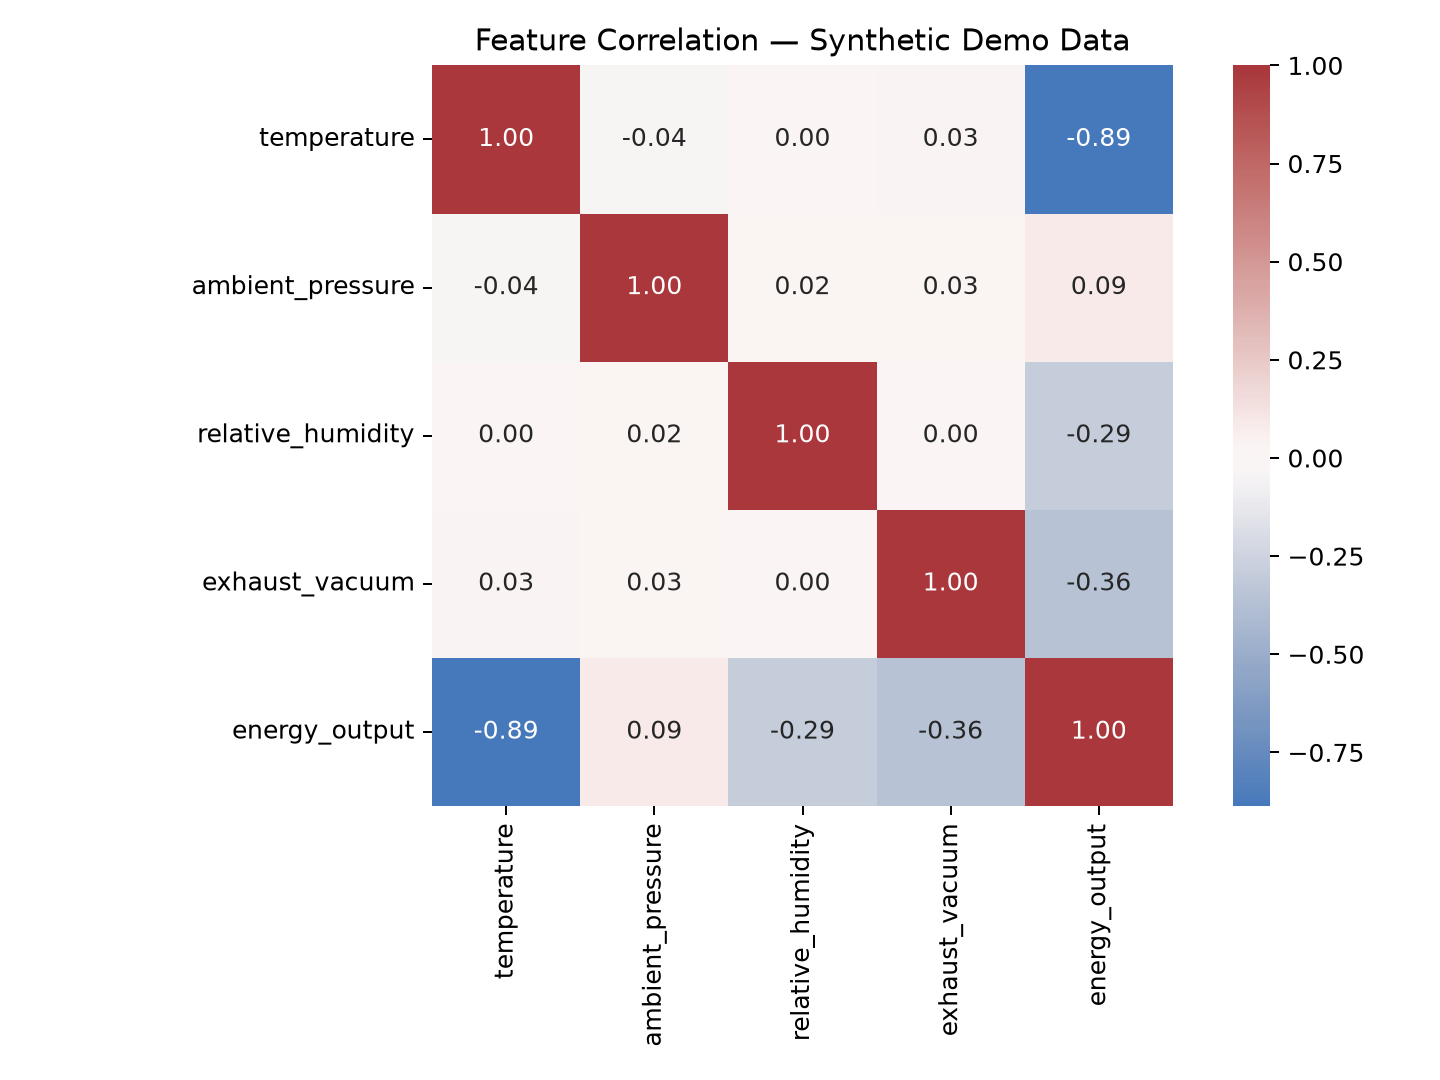

outputs/charts/energy_output_distribution.png


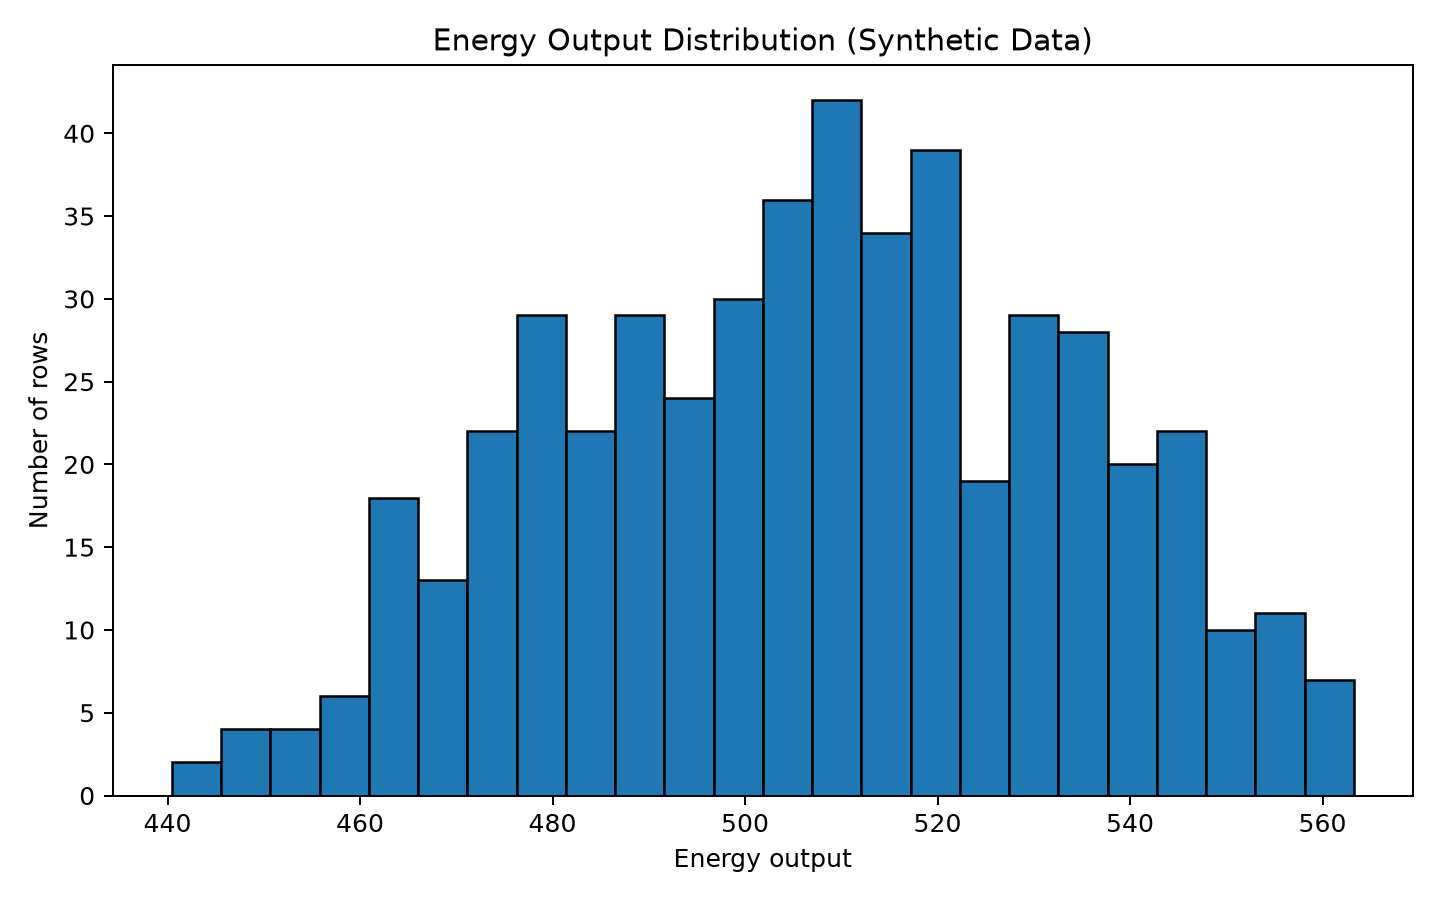

outputs/ml/actual_vs_predicted.png


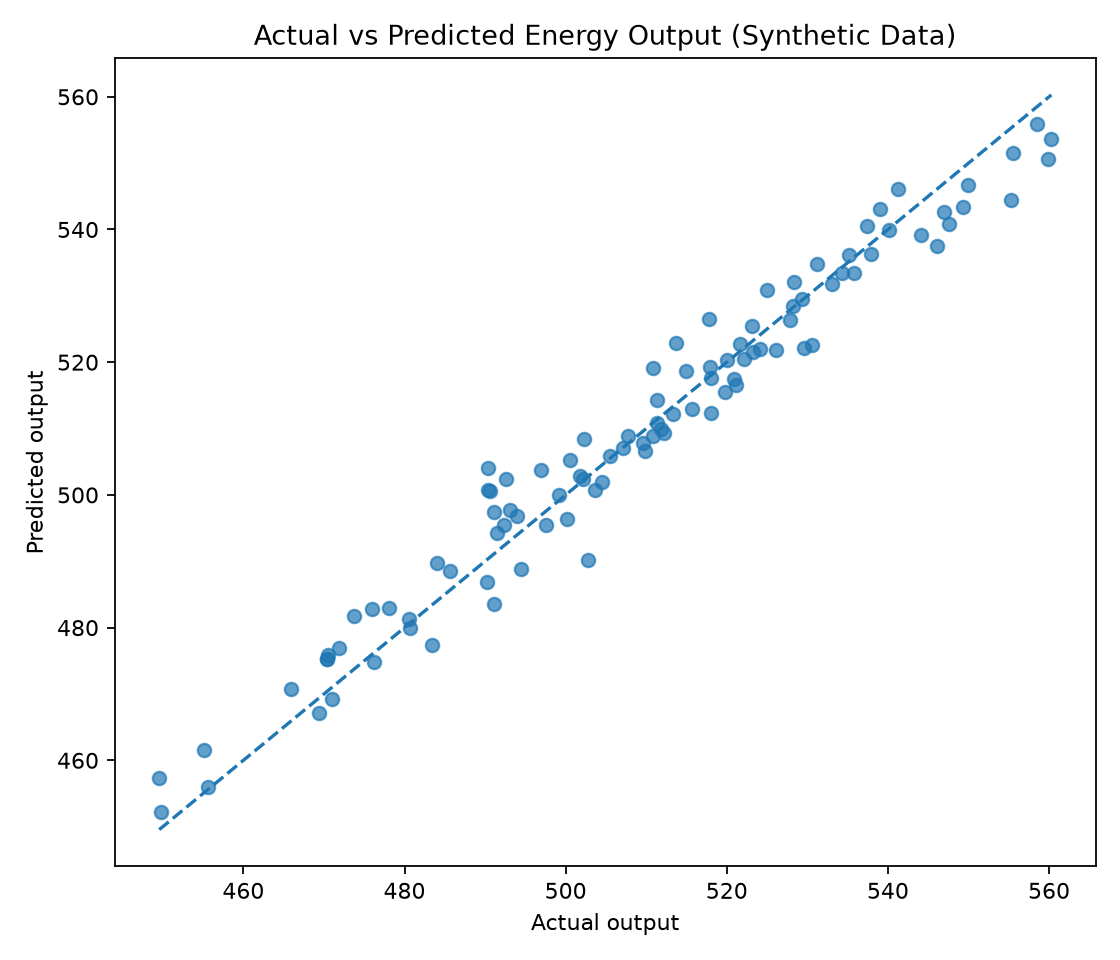

{
  "rows_used": 500,
  "train_rows": 400,
  "test_rows": 100,
  "mae": 4.075851499999963,
  "rmse": 5.066711846365758,
  "r2": 0.9628014228441282,
  "note": "Synthetic demonstration data; metrics are not industrial performance claims."
}


In [ ]:
from IPython.display import display, Image
for img in [PROJECT/'outputs/charts/correlation_heatmap.png', PROJECT/'outputs/charts/energy_output_distribution.png', PROJECT/'outputs/ml/actual_vs_predicted.png']:
    if img.exists():
        print(img.relative_to(PROJECT))
        display(Image(filename=str(img)))
print((PROJECT/'outputs/ml/metrics.json').read_text())

## 5. Run unit tests

In [ ]:
import os
import sys
from pathlib import Path

PROJECT_DIR = Path("/content/COMP4651-professional-portfolio")

os.chdir(PROJECT_DIR)
sys.path.insert(0, str(PROJECT_DIR))

print("Working directory:", os.getcwd())
print("src folder exists:", (PROJECT_DIR / "src").is_dir())
print("src files:", list((PROJECT_DIR / "src").glob("*.py")))

Working directory: /content/COMP4651-professional-portfolio
src folder exists: True
src files: [PosixPath('/content/COMP4651-professional-portfolio/src/__init__.py'), PosixPath('/content/COMP4651-professional-portfolio/src/log_analysis.py'), PosixPath('/content/COMP4651-professional-portfolio/src/visualize.py'), PosixPath('/content/COMP4651-professional-portfolio/src/generate_data.py'), PosixPath('/content/COMP4651-professional-portfolio/src/ml_pipeline.py'), PosixPath('/content/COMP4651-professional-portfolio/src/word_count.py')]


In [ ]:
%cd /content/COMP4651-professional-portfolio

import sys
sys.path.insert(0, "/content/COMP4651-professional-portfolio")

!python -m pytest -q

/content
...                                                                      [100%]
3 passed in 0.03s


In [ ]:
%cd /content/COMP4651-professional-portfolio

!python -m src.generate_data
!python -m src.visualize
!python -m src.ml_pipeline

/content
Sample datasets generated in /content/COMP4651-professional-portfolio/data
/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
Charts saved to outputs/charts
/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
{
  "rows_used": 500,
  "train_rows": 400,
  "test_rows": 100,
  "mae": 4.075851499999959,
  "rmse": 5.066711846365753,
  "r2": 0.9628014228441283,
  "note": "Synthetic demonstration data; metrics are not industrial performance claims."
}
Model metrics and chart saved to outputs/ml


## 6. Optional: run the PySpark word-count demo
If this cell fails because Java/Spark is unavailable in the current runtime, the rest of the portfolio (datasets, log analytics, ML, and charts) can still be generated. Colab may require installing Java and restarting the runtime.

In [ ]:
import subprocess, os
try:
    result = subprocess.run(['python','-m','src.word_count','--input','data/sample_text.txt','--output','outputs/word_count'], cwd=str(PROJECT), text=True, capture_output=True, timeout=180)
    print(result.stdout)
    if result.returncode != 0:
        print('Spark demo did not complete in this runtime:')
        print(result.stderr[-4000:])
    else:
        print('Spark word-count output created.')
except Exception as e:
    print('Spark demo skipped:', repr(e))

[0.022s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.022s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Word counts saved to /content/COMP4651-professional-portfolio/outputs/word_count

Spark word-count output created.


## 7. Package the complete portfolio as a ZIP
The ZIP includes project source, docs, synthetic data, and outputs generated in this run.

In [ ]:
# Keep the generated project folder clean from runtime caches.
for p in list(PROJECT.rglob('__pycache__')) + list(PROJECT.rglob('.pytest_cache')):
    if p.is_dir(): shutil.rmtree(p, ignore_errors=True)
zip_path = Path('/content/COMP4651-professional-portfolio-colab.zip')
if zip_path.exists(): zip_path.unlink()
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for p in PROJECT.rglob('*'):
        if p.is_file(): zf.write(p, p.relative_to(PROJECT.parent))
print('ZIP ready:', zip_path, 'size:', round(zip_path.stat().st_size/1024, 1), 'KB')

ZIP ready: /content/COMP4651-professional-portfolio-colab.zip size: 223.8 KB


In [ ]:
from google.colab import files
files.download('/content/COMP4651-professional-portfolio-colab.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>